# Problema 2 — Regresión en Boston Housing

Dataset clásico de 506 observaciones y 13 atributos del **Boston Housing**. Objetivo: predecir el valor mediano de las viviendas (`medv`).

Fuente: censo de EE.UU. sobre la zona de Boston e información del servicio de censos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

## Análisis exploratorio de datos (EDA)

In [2]:
df = pd.read_csv("/home/santiago/Documentos/ModE/Obligatorio1/problema2/BostonHousing.csv")

print("Dimensiones:", df.shape)
print("Columnas:", list(df.columns))
print("\nTipos de dato:\n", df.dtypes.to_string())
print("\nPrimeras filas:\n", df.head().to_string())
print("\nResumen estadístico:\n", df.describe().T.round(2).to_string())

Dimensiones: (506, 14)
Columnas: ['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax', 'ptratio', 'b', 'lstat', 'medv']

Tipos de dato:
 crim       float64
zn         float64
indus      float64
chas         int64
nox        float64
rm         float64
age        float64
dis        float64
rad          int64
tax          int64
ptratio    float64
b          float64
lstat      float64
medv       float64

Primeras filas:
       crim    zn  indus  chas    nox     rm   age     dis  rad  tax  ptratio       b  lstat  medv
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296     15.3  396.90   4.98  24.0
1  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242     17.8  396.90   9.14  21.6
2  0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242     17.8  392.83   4.03  34.7
3  0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222     18.7  394.63   2.94  33.4
4  0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222   

In [3]:
print("Valores nulos por columna:\n", df.isna().sum().to_string())
print("Filas duplicadas:", df.duplicated().sum())

const = [col for col in df.columns if df[col].nunique() <= 1]
print("Columnas constantes:", const if const else "ninguna")

print("\nColumnas con ceros (¿posible dato faltante codificado como 0?):")
for col in df.columns:
    nz = (df[col] == 0).sum()
    if nz:
        print(f"  {col}: {nz} ceros ({100*nz/len(df):.1f}%)")

Valores nulos por columna:
 crim       0
zn         0
indus      0
chas       0
nox        0
rm         0
age        0
dis        0
rad        0
tax        0
ptratio    0
b          0
lstat      0
medv       0
Filas duplicadas: 0
Columnas constantes: ninguna

Columnas con ceros (¿posible dato faltante codificado como 0?):
  zn: 372 ceros (73.5%)
  chas: 471 ceros (93.1%)


In [4]:
target = "medv"
corr = df.corr(numeric_only=True)[target].sort_values()
print("Correlación de cada feature con", target + ":")
print(corr.round(3).to_string())

Correlación de cada feature con medv:
lstat     -0.738
ptratio   -0.508
indus     -0.484
tax       -0.469
nox       -0.427
crim      -0.388
rad       -0.382
age       -0.377
chas       0.175
dis        0.250
b          0.333
zn         0.360
rm         0.695
medv       1.000


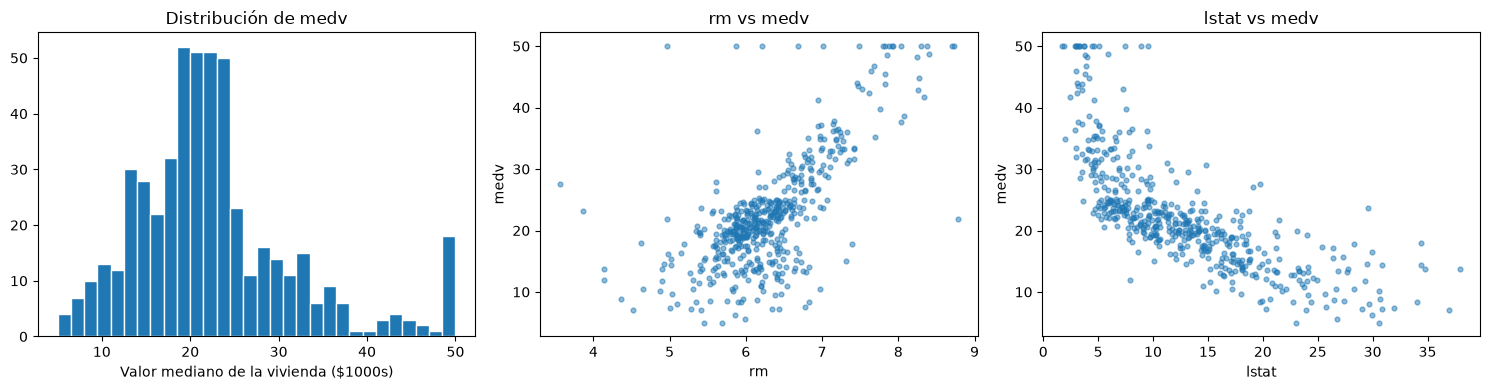

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(df[target], bins=30, edgecolor="white")
axes[0].set_title(f"Distribución de {target}")
axes[0].set_xlabel("Valor mediano de la vivienda ($1000s)")

for ax, col in zip(axes[1:], ["rm", "lstat"]):
    ax.scatter(df[col], df[target], alpha=0.5, s=12)
    ax.set_xlabel(col)
    ax.set_ylabel(target)
    ax.set_title(f"{col} vs {target}")

plt.tight_layout()
plt.show()

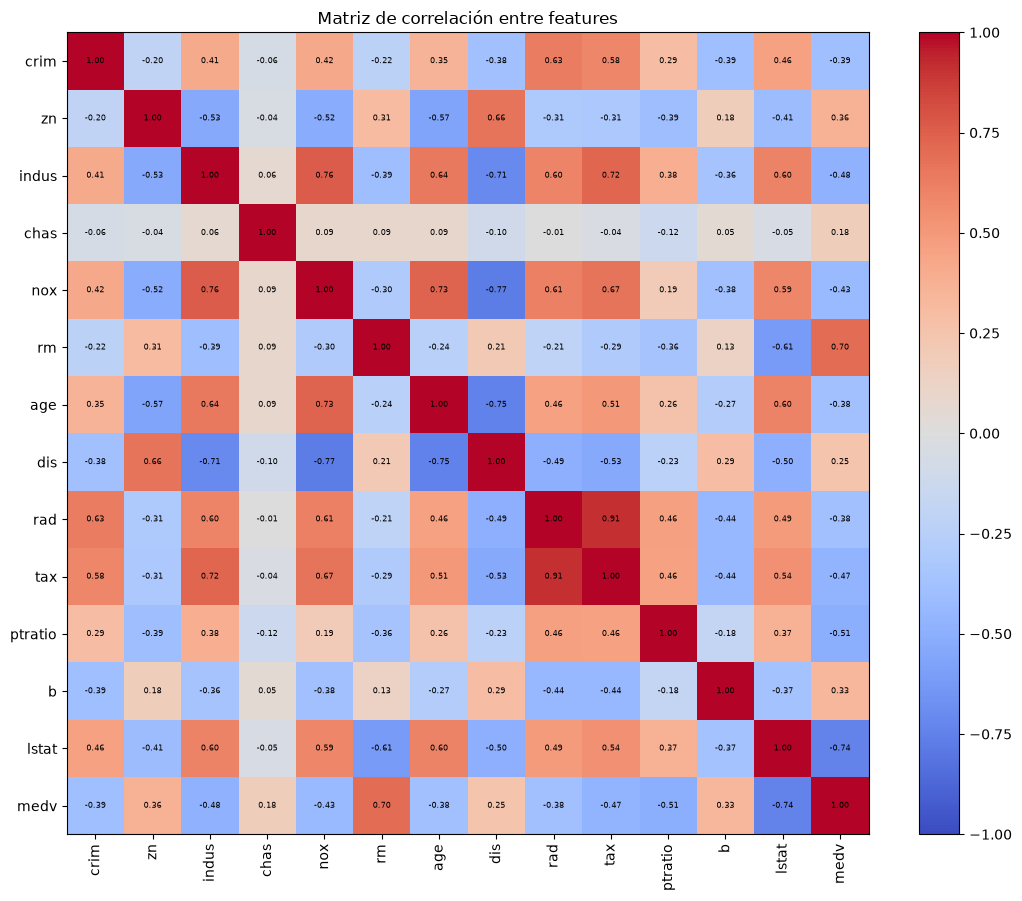

In [6]:
corr_all = df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr_all.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_all.columns)), corr_all.columns, rotation=90)
ax.set_yticks(range(len(corr_all.columns)), corr_all.columns)
for i in range(len(corr_all)):
    for j in range(len(corr_all)):
        ax.text(j, i, f"{corr_all.values[i, j]:.2f}", ha="center", va="center", fontsize=6)
ax.set_title("Matriz de correlación entre features")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

**Primeras observaciones del EDA** (completar/ajustar):

- No hay valores nulos ni filas duplicadas; todas las columnas son numéricas.
- `chas` es binaria y con 93% de ceros; `zn` tiene 74% de ceros — son valores reales, no faltantes.
- `medv` tiene media ≈ 22.5 con desvío ≈ 9.2.
- Las features con mayor correlación linear con `medv`: `rm` (+0.70) y `lstat` (−0.74).

## Modelado

In [7]:
X = df.drop(columns=[target])
y = df[target]

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# grado del polinomio: 1 = lineal, 2 = cuadrático, 3 = cúbico
# El scaler va despues de generar las features polinomiales para que
# Ridge penalice todos los términos (x, x², x³) por igual
for grado in [1, 2, 3]:
    pl = make_pipeline(PolynomialFeatures(degree=grado, include_bias=False), StandardScaler(), LinearRegression())
    pl.fit(X_train, y_train)
    mse_train = mean_squared_error(y_train, pl.predict(X_train))
    mse_val = mean_squared_error(y_val, pl.predict(X_val))
    print(f"polinomio grado {grado}: MSE train={mse_train:.2f}, val = {mse_val:.2f}")

polinomio grado 1: MSE train=21.64, val = 24.29
polinomio grado 2: MSE train=5.13, val = 14.26
polinomio grado 3: MSE train=0.04, val = 4988.47


El bucle entrena regresión lineal con **features polinomiales** recorriendo el `grado`: `1` = solo las características originales, `2` = + términos cuadráticos, `3` = + términos cúbicos. Es la comparación requerida de MSE vs grado del polinomio.

**Sobreajuste:** fijarse que con `grado 3` sin regularizar el `MSE train ≈ 0` (el modelo memoriza los datos) pero el `MSE val ≈ 4988` (generaliza mal). Es el caso clásico alta varianza que Ridge corrige.

In [8]:
grid = make_pipeline(PolynomialFeatures(degree=3, include_bias=False), StandardScaler(), Ridge())
param = {"ridge__alpha": np.logspace(-3, 3, 30)}
gs = GridSearchCV(grid, param, cv=5, scoring="neg_mean_squared_error")
gs.fit(X_train, y_train)
print("Mejor lambda:", gs.best_params_)

# Evaluar el mejor modelo Ridge en train y validación
mejor = gs.best_estimator_
mse_train = mean_squared_error(y_train, mejor.predict(X_train))
mse_val = mean_squared_error(y_val, mejor.predict(X_val))
print(f"Ridge óptimo (grado 3): MSE train={mse_train:.2f}  val={mse_val:.2f}")

Mejor lambda: {'ridge__alpha': np.float64(5.298316906283707)}
Ridge óptimo (grado 3): MSE train=5.21  val=10.32
